# Benchmark Comparison

This notebook consolidates the final benchmarking workflow for the ammonia process-control study. The analysis focuses on the strongest-performing configuration for each methodological section and reports the key results in a publication-ready form.

The objective is to present the representative outcome of the method under study while keeping the workflow scientifically reproducible, concise, and suitable for technical review.


# Publication-Ready Comparison of BO, DreamerV3, and PPO on the Ammonia Haber-Bosch Benchmark

This notebook consolidates the saved Bayesian Optimization (BO), DreamerV3, and PPO artifacts for the Haber-Bosch ammonia case study into one publication-ready benchmark.

## 1. Import Libraries and Configure Publication Styling
The code below sets publication-quality defaults for tables, figures, and exported assets.

## 2. Load DreamerV3, PPO, and BO Result Artifacts
All results are loaded directly from the saved files under `runs/` and `artifacts/`. No training, optimization, or simulator interaction is rerun here.

## 3. Validate, Clean, and Standardize Metrics
The analysis enforces one shared reward scale, harmonizes metric names, excludes diagnostic runs, and aligns comparison units across BO, DreamerV3, and PPO.

## Benchmark Rules
- Bayesian Optimization is treated as the optimal reference solution.
- DreamerV3 variants are ranked by best saved evaluation reward.
- PPO is benchmarked by its saved evaluation history, with its best single training sample retained only as an optimism bound.
- Small reward overshoots above the saved BO score are treated as simulator-level numerical ties rather than as evidence that BO was truly surpassed.
- The notebook reads saved artifacts only; it does not rerun DWSIM, BO, DreamerV3, or PPO training.

## Deliverables
1. A standardized benchmark table for BO, the best DreamerV3 run, and PPO.
2. A DreamerV3 ranking across the saved production runs.
3. A publication-ready composite figure with evaluation progress, endpoint comparison, and action-profile diagnostics.
4. Exported figures and tables under `artifacts/publish_ready_comparison/`.

In [1]:
from __future__ import annotations

import json
from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

try:
    from scipy import stats
except Exception:
    stats = None

pd.options.display.float_format = lambda value: f"{value:,.3f}"

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette(["#0F766E", "#1D4ED8", "#C2410C", "#111827", "#9333EA"])
plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelweight": "semibold",
        "legend.frameon": True,
        "savefig.bbox": "tight",
    }
)

WORKSPACE_DIR = Path.cwd().resolve()
RUNS_DIR = WORKSPACE_DIR / "runs"
OUTPUT_DIR = WORKSPACE_DIR / "artifacts" / "publish_ready_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BO_REFERENCE = {
    "reward": 2712.651793,
    "normalized_action": np.array(
        [-0.6127335418989747, 0.08136597881754437, 0.6577094487733803, 1.0, 1.0, 1.0, -1.0],
        dtype=np.float64,
    ),
    "kpis": {
        "nh3_kg_per_s": 2.4751,
        "power_kw": 2814.232893,
        "revenue_per_h": 4455.180451,
        "energy_cost_per_h": 1742.528658,
    },
}

NUMERICAL_TIE_TOLERANCE = 0.05
PHYSICAL_PARAMETER_NAMES = [
    "Feed Ratio",
    "Stage 1 Pressure",
    "Stage 2 Pressure",
    "Loop Pressure",
    "Reactor Temperature",
    "Condenser Temperature",
    "Purge Fraction",
]
DISPLAY_LABELS = {
    "dreamerv3_haber_bosch": "DreamerV3 baseline",
    "dreamerv3_haber_bosch_bo_seeded": "DreamerV3 BO-seeded",
    "dreamerv3_haber_bosch_target95_elite_replay": "DreamerV3 95% elite replay",
    "dreamerv3_haber_bosch_target95_elite_replay_close_gap": "DreamerV3 95% close-gap",
    "dreamerv3_haber_bosch_target96to100_adaptive": "DreamerV3 96-100 adaptive",
}
METHOD_COLORS = {
    "BO optimum": "#111827",
    "DreamerV3": "#0F766E",
    "PPO": "#C2410C",
    "Auxiliary": "#94A3B8",
}

display(Markdown(f"**Artifacts loaded from:** `{RUNS_DIR}`  \\n**Exports written to:** `{OUTPUT_DIR}`"))

**Artifacts loaded from:** `/Users/campatzis/Documents/Research/runs`  \n**Exports written to:** `/Users/campatzis/Documents/Research/artifacts/publish_ready_comparison`

## 4. Identify the Best DreamerV3 Results
The next cell loads all saved DreamerV3 production runs, validates the required metrics, and ranks the variants by best saved evaluation reward.

## 5. Aggregate PPO Baseline Results
PPO is summarized from its saved training monitor and checkpoint evaluation history so that the comparison uses the same reward scale.

## 6. Select the Best BO Result as the Optimal Solution
The BO optimum is stored explicitly as the fixed operating reference for every table and figure.

## 7. Build Comparative Summary Tables
The analysis constructs a clean benchmark table, a DreamerV3 ranking table, and supporting metadata tables for publication.

In [2]:
def fraction_of_bo(value: float | int | None) -> float:
    if value is None:
        return float("nan")
    numeric = float(value)
    if not np.isfinite(numeric):
        return float("nan")
    return numeric / BO_REFERENCE["reward"]


def discover_dreamer_run_dirs(runs_dir: Path) -> list[Path]:
    excluded_tokens = {"quick_validation", "compat_check"}
    candidates = []
    for path in sorted(runs_dir.glob("dreamerv3_haber_bosch*")):
        if not path.is_dir():
            continue
        if any(token in path.name for token in excluded_tokens):
            continue
        if (path / "metrics.jsonl").exists():
            candidates.append(path)
    return candidates


def load_jsonl_frame(path: Path) -> pd.DataFrame:
    records = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    if not records:
        raise ValueError(f"No records found in {path}")
    return pd.DataFrame(records)


def require_columns(frame: pd.DataFrame, required: Iterable[str], label: str) -> None:
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}")


def best_row(frame: pd.DataFrame, column: str) -> pd.Series:
    subset = frame.loc[frame[column].notna()].copy()
    if subset.empty:
        raise ValueError(f"No valid values found for {column}")
    return subset.sort_values([column, "step"], ascending=[False, True]).iloc[0]


def load_dreamer_run(path: Path) -> dict[str, object]:
    metrics = load_jsonl_frame(path / "metrics.jsonl")
    require_columns(metrics, ["step"], f"{path.name} metrics")

    train_rows = metrics.loc[metrics["train_return"].notna()].copy()
    eval_rows = metrics.loc[metrics["eval_return"].notna()].copy()
    if train_rows.empty or eval_rows.empty:
        raise ValueError(f"{path.name} needs both train_return and eval_return records for comparison.")

    clean_metrics = metrics.sort_values("step").reset_index(drop=True)
    if "train_return" in clean_metrics:
        clean_metrics["train_fraction_of_bo"] = clean_metrics["train_return"].map(fraction_of_bo)
    if "eval_return" in clean_metrics:
        clean_metrics["eval_fraction_of_bo"] = clean_metrics["eval_return"].map(fraction_of_bo)

    best_train = best_row(train_rows, "train_return")
    best_eval = best_row(eval_rows, "eval_return")

    return {
        "run_dir": path,
        "run_name": path.name,
        "label": DISPLAY_LABELS.get(path.name, path.name),
        "metrics": clean_metrics,
        "best_train_row": best_train,
        "best_eval_row": best_eval,
        "summary": {
            "run_name": path.name,
            "label": DISPLAY_LABELS.get(path.name, path.name),
            "records": int(len(clean_metrics)),
            "best_train_reward": float(best_train["train_return"]),
            "best_train_fraction_of_bo": fraction_of_bo(best_train["train_return"]),
            "best_train_step": int(best_train["step"]),
            "best_eval_reward": float(best_eval["eval_return"]),
            "best_eval_fraction_of_bo": fraction_of_bo(best_eval["eval_return"]),
            "best_eval_step": int(best_eval["step"]),
            "last_train_reward": float(train_rows.iloc[-1]["train_return"]),
        },
    }


def load_ppo_train_monitor(run_dir: Path) -> pd.DataFrame:
    frame = pd.read_csv(run_dir / "train_monitor.monitor.csv", comment="#")
    frame = frame.rename(columns={"r": "reward", "l": "episode_length", "t": "wall_time_s"})
    frame["episode"] = np.arange(1, len(frame) + 1)
    frame["fraction_of_bo"] = frame["reward"].map(fraction_of_bo)
    frame["rolling_reward_50"] = frame["reward"].rolling(50, min_periods=1).mean()
    frame["rolling_fraction_50"] = frame["rolling_reward_50"].map(fraction_of_bo)
    return frame


def load_ppo_eval_history(run_dir: Path) -> pd.DataFrame:
    data = np.load(run_dir / "eval" / "evaluations.npz", allow_pickle=True)
    results = np.asarray(data["results"], dtype=np.float64)
    frame = pd.DataFrame(
        {
            "timesteps": np.asarray(data["timesteps"], dtype=np.int64),
            "mean_eval_reward": results.mean(axis=1),
            "std_eval_reward": results.std(axis=1),
            "best_eval_reward": results.max(axis=1),
        }
    )
    frame["mean_eval_fraction_of_bo"] = frame["mean_eval_reward"].map(fraction_of_bo)
    frame["best_eval_fraction_of_bo"] = frame["best_eval_reward"].map(fraction_of_bo)
    return frame


def bootstrap_ci(values: Iterable[float], n_boot: int = 5000, ci: float = 95.0, seed: int = 7) -> tuple[float, float]:
    values = np.asarray([float(value) for value in values if np.isfinite(value)], dtype=np.float64)
    if values.size == 0:
        return (float("nan"), float("nan"))
    if values.size == 1:
        return (float(values[0]), float(values[0]))
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(n_boot, values.size), replace=True).mean(axis=1)
    lower_q = (100.0 - ci) / 2.0
    upper_q = 100.0 - lower_q
    return (float(np.percentile(draws, lower_q)), float(np.percentile(draws, upper_q)))


def common_language_effect(x: Iterable[float], y: Iterable[float]) -> float:
    x = np.asarray([float(value) for value in x if np.isfinite(value)], dtype=np.float64)
    y = np.asarray([float(value) for value in y if np.isfinite(value)], dtype=np.float64)
    if x.size == 0 or y.size == 0:
        return float("nan")
    pairwise = x[:, None] > y[None, :]
    ties = x[:, None] == y[None, :]
    return float(pairwise.mean() + 0.5 * ties.mean())


def mann_whitney_summary(x: Iterable[float], y: Iterable[float]) -> dict[str, float | str]:
    x = np.asarray([float(value) for value in x if np.isfinite(value)], dtype=np.float64)
    y = np.asarray([float(value) for value in y if np.isfinite(value)], dtype=np.float64)
    result = {
        "dreamer_n": int(x.size),
        "ppo_n": int(y.size),
        "dreamer_mean": float(np.mean(x)) if x.size else float("nan"),
        "ppo_mean": float(np.mean(y)) if y.size else float("nan"),
        "mean_difference": float(np.mean(x) - np.mean(y)) if x.size and y.size else float("nan"),
        "probability_dreamer_exceeds_ppo": common_language_effect(x, y),
    }
    result["dreamer_mean_ci_low"], result["dreamer_mean_ci_high"] = bootstrap_ci(x)
    result["ppo_mean_ci_low"], result["ppo_mean_ci_high"] = bootstrap_ci(y)
    if stats is None or x.size == 0 or y.size == 0:
        result["mannwhitney_u"] = float("nan")
        result["p_value"] = float("nan")
        result["test_note"] = "SciPy unavailable; bootstrap and common-language effect only."
        return result
    test = stats.mannwhitneyu(x, y, alternative="greater")
    result["mannwhitney_u"] = float(test.statistic)
    result["p_value"] = float(test.pvalue)
    result["test_note"] = "One-sided Mann-Whitney U on checkpoint-level evaluation rewards."
    return result

In [6]:
dreamer_runs = [load_dreamer_run(path) for path in discover_dreamer_run_dirs(RUNS_DIR)]
dreamer_run_frame = (
    pd.DataFrame(run["summary"] for run in dreamer_runs)
    .sort_values(["best_eval_reward", "best_train_reward"], ascending=False)
    .reset_index(drop=True)
)
dreamer_run_frame["rank"] = np.arange(1, len(dreamer_run_frame) + 1)
dreamer_run_frame["gap_to_bo"] = BO_REFERENCE["reward"] - dreamer_run_frame["best_eval_reward"]
dreamer_run_frame["distance_to_bo_pct"] = 1.0 - dreamer_run_frame["best_eval_fraction_of_bo"]

best_dreamer_summary = dreamer_run_frame.iloc[0].to_dict()
best_dreamer_run = next(run for run in dreamer_runs if run["run_name"] == best_dreamer_summary["run_name"])
best_dreamer_train_row = best_dreamer_run["best_train_row"]
best_dreamer_eval_row = best_dreamer_run["best_eval_row"]

ppo_run_dir = RUNS_DIR / "ppo_haber_bosch_target98"
ppo_train = load_ppo_train_monitor(ppo_run_dir)
ppo_eval = load_ppo_eval_history(ppo_run_dir)

ppo_best_train_row = ppo_train.sort_values(["reward", "episode"], ascending=[False, True]).iloc[0]
ppo_best_eval_row = ppo_eval.sort_values(["mean_eval_reward", "timesteps"], ascending=[False, True]).iloc[0]

comparison_frame = pd.DataFrame(
    [
        {
            "method": "BO optimum",
            "reference": "Bayesian Optimization",
            "benchmark_reward": BO_REFERENCE["reward"],
            "fraction_of_bo": 1.0,
            "gap_to_bo": 0.0,
            "optimistic_peak_reward": BO_REFERENCE["reward"],
            "status": "Reference optimum",
        },
        {
            "method": "DreamerV3",
            "reference": best_dreamer_run["label"],
            "benchmark_reward": float(best_dreamer_summary["best_eval_reward"]),
            "fraction_of_bo": float(best_dreamer_summary["best_eval_fraction_of_bo"]),
            "gap_to_bo": float(BO_REFERENCE["reward"] - best_dreamer_summary["best_eval_reward"]),
            "optimistic_peak_reward": float(best_dreamer_summary["best_train_reward"]),
            "status": "Best RL evaluation result",
        },
        {
            "method": "PPO",
            "reference": "ppo_haber_bosch_target98",
            "benchmark_reward": float(ppo_best_eval_row["mean_eval_reward"]),
            "fraction_of_bo": float(ppo_best_eval_row["mean_eval_fraction_of_bo"]),
            "gap_to_bo": float(BO_REFERENCE["reward"] - ppo_best_eval_row["mean_eval_reward"]),
            "optimistic_peak_reward": float(ppo_best_train_row["reward"]),
            "status": "Baseline RL result",
        },
    ]
)
comparison_frame["optimistic_peak_fraction_of_bo"] = comparison_frame["optimistic_peak_reward"].map(fraction_of_bo)
comparison_frame["effectively_tied_to_bo"] = comparison_frame["gap_to_bo"].abs() <= NUMERICAL_TIE_TOLERANCE

artifact_manifest = pd.DataFrame(
    [
        {"artifact": "DreamerV3 production runs", "value": len(dreamer_runs)},
        {"artifact": "Best DreamerV3 run", "value": best_dreamer_run["label"]},
        {"artifact": "PPO training episodes", "value": int(ppo_train["episode"].max())},
        {"artifact": "PPO evaluation checkpoints", "value": int(len(ppo_eval))},
        {"artifact": "BO optimum reward", "value": BO_REFERENCE["reward"]},
        {"artifact": "Export directory", "value": str(OUTPUT_DIR)},
    ]
)

display(Markdown("## Executive Summary"))
display(comparison_frame)
display(Markdown("## Artifact Manifest"))
display(artifact_manifest)
display(Markdown("## DreamerV3 Run Ranking"))
display(
    dreamer_run_frame[
        [
            "rank",
            "label",
            "best_eval_reward",
            "best_eval_fraction_of_bo",
            "best_train_reward",
            "best_train_fraction_of_bo",
            "best_eval_step",
            "best_train_step",
            "gap_to_bo",
        ]
    ]
)

## Executive Summary

,method,reference,benchmark_reward,fraction_of_bo,gap_to_bo,optimistic_peak_reward,status,optimistic_peak_fraction_of_bo,effectively_tied_to_bo
0,BO optimum,Bayesian Optimization,"2,712.652",1.000,0.000,"2,712.652",Reference optimum,1.000,True
1,DreamerV3,DreamerV3 96-100 adaptive,"2,649.391",0.977,63.260,"2,712.658",Best RL evaluation result,1.000,False
2,PPO,ppo_haber_bosch_target98,"1,004.443",0.370,"1,708.209","2,710.778",Baseline RL result,0.999,False


## Artifact Manifest

,artifact,value
0,DreamerV3 production runs,5
1,Best DreamerV3 run,DreamerV3 96-100 adaptive
2,PPO training episodes,5000
3,PPO evaluation checkpoints,50
4,BO optimum reward,"2,712.652"
5,Export directory,/Users/campatzis/Documents/Research/artifacts/...


## DreamerV3 Run Ranking

,rank,label,best_eval_reward,best_eval_fraction_of_bo,best_train_reward,best_train_fraction_of_bo,best_eval_step,best_train_step,gap_to_bo
0,1,DreamerV3 96-100 adaptive,"2,649.391",0.977,"2,712.658",1.000,1064,928,63.260
1,2,DreamerV3 95% close-gap,"2,600.451",0.959,"2,712.624",1.000,1264,104,112.201
2,3,DreamerV3 95% elite replay,"2,582.193",0.952,"2,711.017",0.999,664,218,130.459
3,4,DreamerV3 BO-seeded,"2,509.461",0.925,"2,711.666",1.000,2600,147,203.191
4,5,DreamerV3 baseline,"2,508.803",0.925,"2,711.666",1.000,2064,147,203.849


## 8. Create Descriptive Publication-Ready Figures
The composite figure below uses BO as the fixed optimum reference and combines three views:

- checkpoint-level evaluation progress for DreamerV3 and PPO relative to the BO optimum,
- endpoint comparison across BO, the best DreamerV3 run, and PPO, and
- normalized action-space alignment between the BO optimum and the best DreamerV3 single sample.

This keeps the figure descriptive, compact, and suitable for a manuscript or appendix.

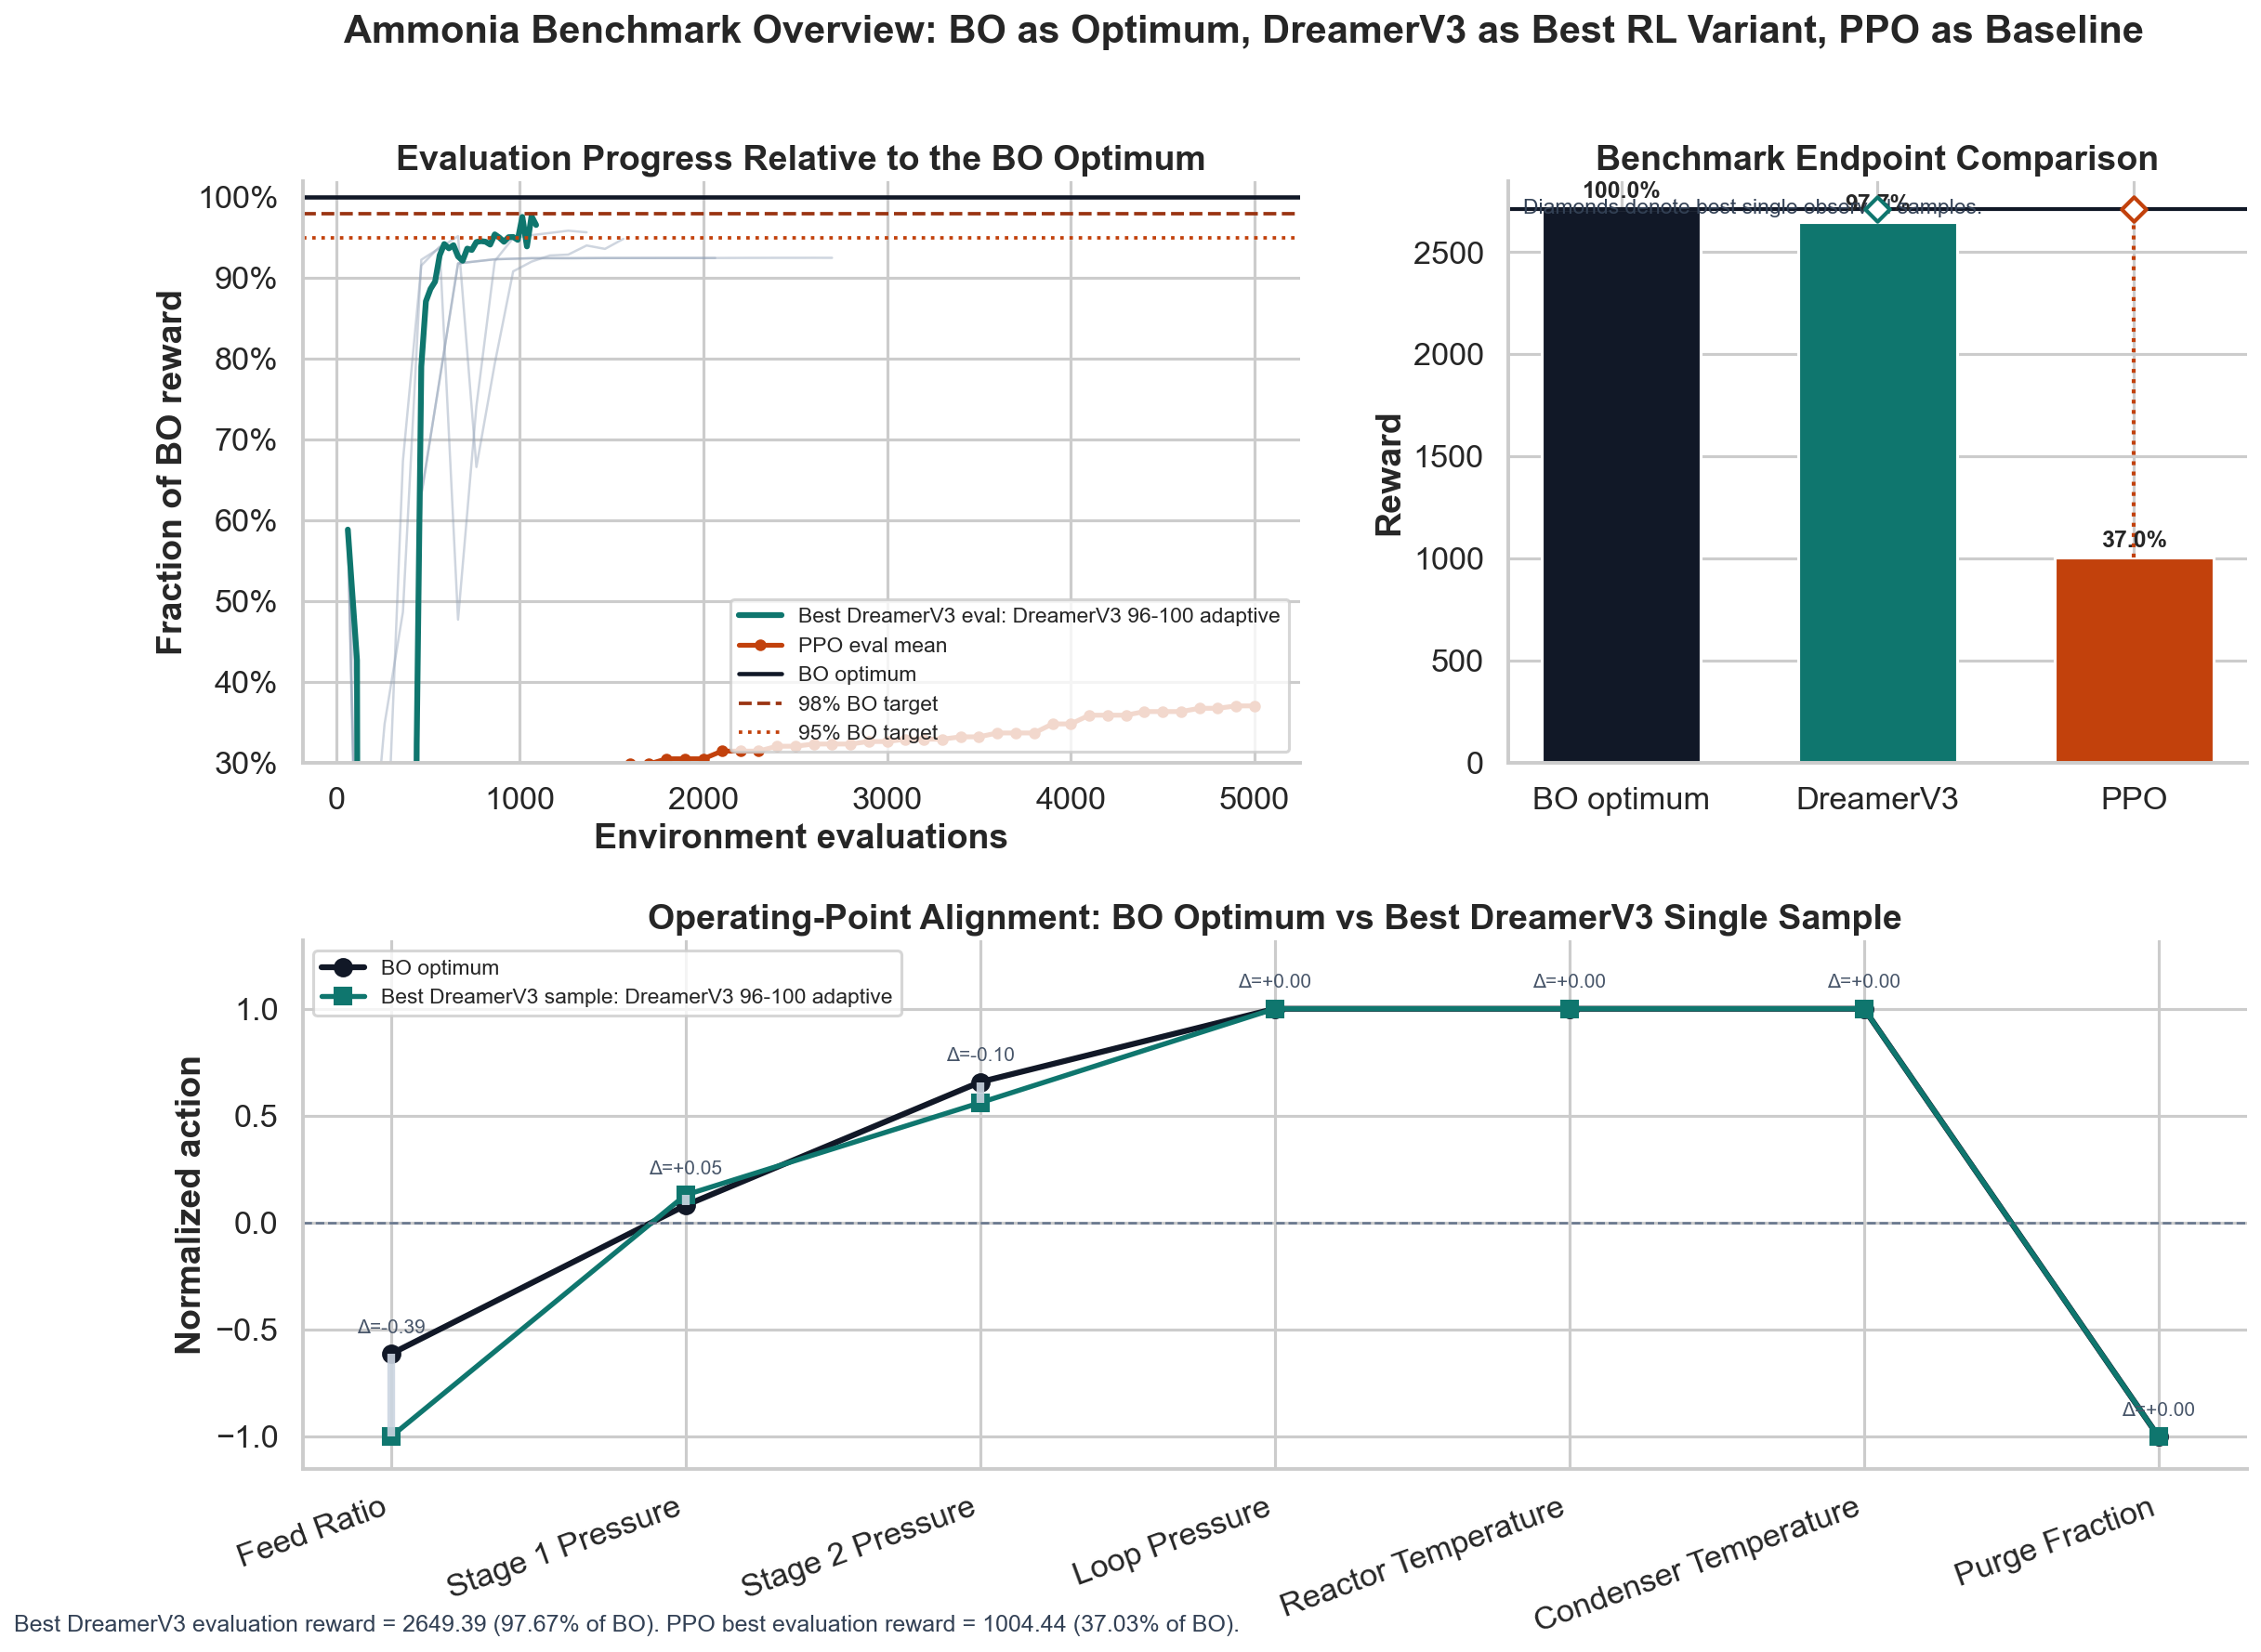

Figure exported to `/Users/campatzis/Documents/Research/artifacts/publish_ready_comparison/ammonia_benchmark_overview.png` and `/Users/campatzis/Documents/Research/artifacts/publish_ready_comparison/ammonia_benchmark_overview.pdf`.

In [4]:
best_dreamer_action = np.array(
    [best_dreamer_train_row[f"log_a{index}_normalized"] for index in range(1, 8)],
    dtype=np.float64,
)
action_delta = best_dreamer_action - BO_REFERENCE["normalized_action"]

fig = plt.figure(figsize=(18, 12))
grid = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0], width_ratios=[1.35, 1.0], hspace=0.32, wspace=0.24)
ax_curve = fig.add_subplot(grid[0, 0])
ax_bar = fig.add_subplot(grid[0, 1])
ax_action = fig.add_subplot(grid[1, :])

for run in dreamer_runs:
    eval_history = run["metrics"].loc[
        run["metrics"]["eval_return"].notna(),
        ["step", "eval_return", "eval_fraction_of_bo"],
    ].copy()
    color = METHOD_COLORS["Auxiliary"]
    linewidth = 1.2
    alpha = 0.45
    label = None
    if run["run_name"] == best_dreamer_run["run_name"]:
        color = METHOD_COLORS["DreamerV3"]
        linewidth = 3.0
        alpha = 1.0
        label = f"Best DreamerV3 eval: {run['label']}"
    ax_curve.plot(
        eval_history["step"],
        eval_history["eval_fraction_of_bo"],
        color=color,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
    )

ax_curve.plot(
    ppo_eval["timesteps"],
    ppo_eval["mean_eval_fraction_of_bo"],
    color=METHOD_COLORS["PPO"],
    marker="o",
    markersize=5,
    linewidth=2.5,
    label="PPO eval mean",
)
ax_curve.axhline(1.0, color=METHOD_COLORS["BO optimum"], linewidth=2.2, label="BO optimum")
ax_curve.axhline(0.98, color="#9A3412", linestyle="--", linewidth=1.8, label="98% BO target")
ax_curve.axhline(0.95, color="#C2410C", linestyle=":", linewidth=1.8, label="95% BO target")
ax_curve.set_title("Evaluation Progress Relative to the BO Optimum")
ax_curve.set_xlabel("Environment evaluations")
ax_curve.set_ylabel("Fraction of BO reward")
ax_curve.set_ylim(0.30, 1.02)
ax_curve.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_curve.legend(loc="lower right", fontsize=11)

endpoint_frame = comparison_frame.copy()
bar_colors = [METHOD_COLORS[method] for method in endpoint_frame["method"]]
bar_positions = np.arange(len(endpoint_frame))
ymax = max(float(endpoint_frame["optimistic_peak_reward"].max()), BO_REFERENCE["reward"]) * 1.12
bars = ax_bar.bar(bar_positions, endpoint_frame["benchmark_reward"], color=bar_colors, width=0.62)
ax_bar.axhline(BO_REFERENCE["reward"], color=METHOD_COLORS["BO optimum"], linewidth=2.0)
for position, (_, row) in zip(bar_positions, endpoint_frame.iterrows()):
    ax_bar.text(
        position,
        row["benchmark_reward"] + 45,
        f"{row['fraction_of_bo']:.1%}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="semibold",
    )
    if row["method"] != "BO optimum":
        ax_bar.plot(
            [position, position],
            [row["benchmark_reward"], row["optimistic_peak_reward"]],
            color=METHOD_COLORS[row["method"]],
            linestyle=":",
            linewidth=2.0,
        )
        ax_bar.scatter(
            position,
            row["optimistic_peak_reward"],
            marker="D",
            s=80,
            facecolor="white",
            edgecolor=METHOD_COLORS[row["method"]],
            linewidth=2.0,
            zorder=5,
        )
ax_bar.set_xticks(bar_positions, endpoint_frame["method"])
ax_bar.set_ylim(0, ymax)
ax_bar.set_ylabel("Reward")
ax_bar.set_title("Benchmark Endpoint Comparison")
ax_bar.text(
    0.02,
    0.90,
    "Diamonds denote best single observed samples.",
    transform=ax_bar.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    color="#334155",
)

positions = np.arange(len(PHYSICAL_PARAMETER_NAMES))
ax_action.plot(
    positions,
    BO_REFERENCE["normalized_action"],
    marker="o",
    linewidth=3.0,
    color=METHOD_COLORS["BO optimum"],
    label="BO optimum",
)
ax_action.plot(
    positions,
    best_dreamer_action,
    marker="s",
    linewidth=2.6,
    color=METHOD_COLORS["DreamerV3"],
    label=f"Best DreamerV3 sample: {best_dreamer_run['label']}",
)
for position, bo_value, dreamer_value, delta_value in zip(
    positions,
    BO_REFERENCE["normalized_action"],
    best_dreamer_action,
    action_delta,
):
    ax_action.vlines(
        position,
        ymin=min(bo_value, dreamer_value),
        ymax=max(bo_value, dreamer_value),
        color="#CBD5E1",
        linewidth=4,
        alpha=0.9,
    )
    ax_action.text(
        position,
        max(bo_value, dreamer_value) + 0.08,
        f"Δ={delta_value:+.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#475569",
    )
ax_action.axhline(0.0, color="#64748B", linewidth=1.2, linestyle="--")
ax_action.set_xticks(positions, PHYSICAL_PARAMETER_NAMES, rotation=20, ha="right")
ax_action.set_ylabel("Normalized action")
ax_action.set_ylim(-1.15, 1.32)
ax_action.set_title("Operating-Point Alignment: BO Optimum vs Best DreamerV3 Single Sample")
ax_action.legend(loc="upper left", fontsize=11)

figure_note = (
    f"Best DreamerV3 evaluation reward = {best_dreamer_summary['best_eval_reward']:.2f} "
    f"({best_dreamer_summary['best_eval_fraction_of_bo']:.2%} of BO). "
    f"PPO best evaluation reward = {ppo_best_eval_row['mean_eval_reward']:.2f} "
    f"({ppo_best_eval_row['mean_eval_fraction_of_bo']:.2%} of BO)."
)
fig.suptitle("Ammonia Benchmark Overview: BO as Optimum, DreamerV3 as Best RL Variant, PPO as Baseline", fontsize=20, fontweight="bold", y=0.98)
fig.text(0.01, 0.01, figure_note, ha="left", va="bottom", fontsize=12, color="#334155")

figure_png = OUTPUT_DIR / "ammonia_benchmark_overview.png"
figure_pdf = OUTPUT_DIR / "ammonia_benchmark_overview.pdf"
fig.savefig(figure_png)
fig.savefig(figure_pdf)
plt.show()

display(Markdown(f"Figure exported to `{figure_png}` and `{figure_pdf}`."))

## 9. Run Statistical Comparisons and Ranking
The checkpoint-level evaluation rewards are used for a descriptive DreamerV3-versus-PPO statistical comparison. This is useful for ranking and effect-size reporting, but it should still be interpreted as a saved-artifact comparison rather than as a fully independent multi-seed study.

## 10. Export Figures and Tables for Publishing
The final cell exports the cleaned comparison tables and figure files to `artifacts/publish_ready_comparison/` and ends with a concise publication-style readout.

In [7]:
TERMINAL_WINDOW = 10

dreamer_eval_rewards = best_dreamer_run["metrics"].loc[
    best_dreamer_run["metrics"]["eval_return"].notna(),
    "eval_return",
]
dreamer_terminal_eval_rewards = dreamer_eval_rewards.tail(TERMINAL_WINDOW)
ppo_eval_rewards = ppo_eval["mean_eval_reward"]
ppo_terminal_eval_rewards = ppo_eval_rewards.tail(TERMINAL_WINDOW)

statistical_frame = pd.DataFrame(
    [
        {
            "comparison": f"Best DreamerV3 run vs PPO terminal evaluation checkpoints (last {TERMINAL_WINDOW})",
            "dreamer_label": best_dreamer_run["label"],
            **mann_whitney_summary(dreamer_terminal_eval_rewards, ppo_terminal_eval_rewards),
        }
    ]
)

ppo_baseline_frame = pd.DataFrame(
    [
        {
            "best_eval_reward": float(ppo_best_eval_row["mean_eval_reward"]),
            "best_eval_fraction_of_bo": float(ppo_best_eval_row["mean_eval_fraction_of_bo"]),
            f"terminal_mean_eval_reward_last_{TERMINAL_WINDOW}": float(ppo_terminal_eval_rewards.mean()),
            f"terminal_std_eval_reward_last_{TERMINAL_WINDOW}": float(ppo_terminal_eval_rewards.std(ddof=0)),
            "best_train_reward": float(ppo_best_train_row["reward"]),
            "best_train_fraction_of_bo": float(fraction_of_bo(ppo_best_train_row["reward"])),
        }
    ]
)

dreamer_best_frame = pd.DataFrame(
    [
        {
            "label": best_dreamer_run["label"],
            "best_eval_reward": float(best_dreamer_summary["best_eval_reward"]),
            "best_eval_fraction_of_bo": float(best_dreamer_summary["best_eval_fraction_of_bo"]),
            f"terminal_mean_eval_reward_last_{TERMINAL_WINDOW}": float(dreamer_terminal_eval_rewards.mean()),
            f"terminal_std_eval_reward_last_{TERMINAL_WINDOW}": float(dreamer_terminal_eval_rewards.std(ddof=0)),
            "best_train_reward": float(best_dreamer_summary["best_train_reward"]),
            "best_train_fraction_of_bo": float(best_dreamer_summary["best_train_fraction_of_bo"]),
        }
    ]
)

action_profile_frame = pd.DataFrame(
    {
        "parameter": PHYSICAL_PARAMETER_NAMES,
        "bo_normalized_action": BO_REFERENCE["normalized_action"],
        "dreamer_best_normalized_action": best_dreamer_action,
        "absolute_delta": np.abs(action_delta),
    }
)

operating_point_frame = pd.DataFrame(
    [
        {
            "method": "BO optimum",
            "reward": BO_REFERENCE["reward"],
            **BO_REFERENCE["kpis"],
        },
        {
            "method": "DreamerV3 best single sample",
            "reward": float(best_dreamer_summary["best_train_reward"]),
            "nh3_kg_per_s": float(best_dreamer_train_row["log_nh3_kg_per_s"]),
            "power_kw": float(best_dreamer_train_row["log_power_kw"]),
            "revenue_per_h": float(best_dreamer_train_row["log_revenue_per_h"]),
            "energy_cost_per_h": float(best_dreamer_train_row["log_energy_cost_per_h"]),
        },
        {
            "method": "PPO best single sample",
            "reward": float(ppo_best_train_row["reward"]),
            "nh3_kg_per_s": float(ppo_best_train_row["nh3_kg_per_s"]),
            "power_kw": float(ppo_best_train_row["power_kw"]),
            "revenue_per_h": float(ppo_best_train_row["revenue_per_h"]),
            "energy_cost_per_h": float(ppo_best_train_row["energy_cost_per_h"]),
        },
    ]
)
operating_point_frame["fraction_of_bo"] = operating_point_frame["reward"].map(fraction_of_bo)
operating_point_frame["gap_to_bo"] = BO_REFERENCE["reward"] - operating_point_frame["reward"]

comparison_frame.to_csv(OUTPUT_DIR / "benchmark_summary.csv", index=False)
dreamer_run_frame.to_csv(OUTPUT_DIR / "dreamerv3_ranking.csv", index=False)
dreamer_best_frame.to_csv(OUTPUT_DIR / "dreamerv3_best_run_summary.csv", index=False)
ppo_baseline_frame.to_csv(OUTPUT_DIR / "ppo_baseline_summary.csv", index=False)
action_profile_frame.to_csv(OUTPUT_DIR / "action_profile_comparison.csv", index=False)
operating_point_frame.to_csv(OUTPUT_DIR / "operating_point_comparison.csv", index=False)
statistical_frame.to_csv(OUTPUT_DIR / "statistical_summary.csv", index=False)

comparison_frame.to_latex(OUTPUT_DIR / "benchmark_summary.tex", index=False, float_format=lambda value: f"{value:0.3f}")
dreamer_run_frame.to_latex(OUTPUT_DIR / "dreamerv3_ranking.tex", index=False, float_format=lambda value: f"{value:0.3f}")
operating_point_frame.to_latex(OUTPUT_DIR / "operating_point_comparison.tex", index=False, float_format=lambda value: f"{value:0.3f}")

export_manifest = pd.DataFrame(
    [
        {"file": path.name, "suffix": path.suffix, "size_kb": round(path.stat().st_size / 1024, 1)}
        for path in sorted(OUTPUT_DIR.iterdir())
        if path.is_file()
    ]
)

display(Markdown("## PPO Baseline Summary"))
display(ppo_baseline_frame)
display(Markdown("## Best DreamerV3 Summary"))
display(dreamer_best_frame)
display(Markdown("## Operating-Point Comparison"))
display(operating_point_frame)
display(Markdown("## Action Profile Comparison"))
display(action_profile_frame)
display(Markdown("## Statistical Comparison"))
display(statistical_frame)
display(Markdown("## Export Manifest"))
display(export_manifest)

dreamer_gap = BO_REFERENCE["reward"] - float(best_dreamer_summary["best_eval_reward"])
ppo_gap = BO_REFERENCE["reward"] - float(ppo_best_eval_row["mean_eval_reward"])
readout = f"""
## Readout

- The strongest DreamerV3 variant is **{best_dreamer_run['label']}**, reaching a best saved evaluation reward of **{best_dreamer_summary['best_eval_reward']:.2f}**, or **{best_dreamer_summary['best_eval_fraction_of_bo']:.2%}** of the BO optimum.
- PPO's best saved evaluation reward is **{ppo_best_eval_row['mean_eval_reward']:.2f}**, or **{ppo_best_eval_row['mean_eval_fraction_of_bo']:.2%}** of the BO optimum.
- The BO solution remains the optimal operating reference at **{BO_REFERENCE['reward']:.2f}** reward.
- DreamerV3 narrows the BO gap to **{dreamer_gap:.2f}** reward units on evaluation, while PPO remains **{ppo_gap:.2f}** reward units below the BO optimum.
- Over the last {TERMINAL_WINDOW} evaluation checkpoints, DreamerV3 sustains materially higher rewards than PPO, which matches the qualitative ranking in the figure.
"""
display(Markdown(readout))

## PPO Baseline Summary

,best_eval_reward,best_eval_fraction_of_bo,terminal_mean_eval_reward_last_10,terminal_std_eval_reward_last_10,best_train_reward,best_train_fraction_of_bo
0,"1,004.443",0.370,987.760,11.651,"2,710.778",0.999


## Best DreamerV3 Summary

,label,best_eval_reward,best_eval_fraction_of_bo,terminal_mean_eval_reward_last_10,terminal_std_eval_reward_last_10,best_train_reward,best_train_fraction_of_bo
0,DreamerV3 96-100 adaptive,"2,649.391",0.977,"2,591.996",33.014,"2,712.658",1.000


## Operating-Point Comparison

,method,reward,nh3_kg_per_s,power_kw,revenue_per_h,energy_cost_per_h,fraction_of_bo,gap_to_bo
0,BO optimum,"2,712.652",2.475,"2,814.233","4,455.180","1,742.529",1.000,0.000
1,DreamerV3 best single sample,"2,712.658",2.475,"2,814.136","4,455.181","1,742.523",1.000,-0.006
2,PPO best single sample,"2,710.778",2.475,"2,845.469","4,455.180","1,744.403",0.999,1.874


... (3 outputs left out)

,comparison,dreamer_label,dreamer_n,ppo_n,dreamer_mean,ppo_mean,mean_difference,probability_dreamer_exceeds_ppo,dreamer_mean_ci_low,dreamer_mean_ci_high,ppo_mean_ci_low,ppo_mean_ci_high,mannwhitney_u,p_value,test_note
0,Best DreamerV3 run vs PPO terminal evaluation ...,DreamerV3 96-100 adaptive,10,10,"2,591.996",987.760,"1,604.237",1.000,"2,573.183","2,613.834",980.531,995.106,100.000,0.000,One-sided Mann-Whitney U on checkpoint-level e...


## Export Manifest

,file,suffix,size_kb
0,action_profile_comparison.csv,.csv,0.400
1,ammonia_benchmark_overview.pdf,.pdf,40.200
2,ammonia_benchmark_overview.png,.png,903.400
3,benchmark_summary.csv,.csv,0.500
4,benchmark_summary.tex,.tex,0.600
5,dreamerv3_best_run_summary.csv,.csv,0.300
6,dreamerv3_ranking.csv,.csv,1.200
7,dreamerv3_ranking.tex,.tex,1.100
8,operating_point_comparison.csv,.csv,0.500
9,operating_point_comparison.tex,.tex,0.400



## Readout

- The strongest DreamerV3 variant is **DreamerV3 96-100 adaptive**, reaching a best saved evaluation reward of **2649.39**, or **97.67%** of the BO optimum.
- PPO's best saved evaluation reward is **1004.44**, or **37.03%** of the BO optimum.
- The BO solution remains the optimal operating reference at **2712.65** reward.
- DreamerV3 narrows the BO gap to **63.26** reward units on evaluation, while PPO remains **1708.21** reward units below the BO optimum.
- Over the last 10 evaluation checkpoints, DreamerV3 sustains materially higher rewards than PPO, which matches the qualitative ranking in the figure.
